---
title: Hidden Markov Model with Control (Part 3)
subtitle: Control a Roomba using Active Inference and RxInfer
author: Kobus Esterhuysen
date: '2024-05-22'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Active Inference
  - RxInfer
  - Julia
image: HMMwithControl.png
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [20]:
#| hide
# BASED ON
    # HMMwithControl3_PORT^v3.ipynb
    # HMMwithControl3_PORT^v2.ipynb
    # HMMwithControl2_PORT^v2.ipynb
# DONE
# v1 starts ------------------------------------------------
# add a motion sensor
# expand s0 to have combinations of its position and occupancy
# clean for publication
# v3 starts ------------------------------------------------
# align with ActiveInference_Notebook_Standards.md (bracket rules before v1.7)
# v4 starts ------------------------------------------------
# align with ActiveInference_Notebook_Standards.md v1.8 (21 Oct 2026)
    # members in round brackets: s^{(t,0)}, A^{(m)}, B^{*(0)}; array positions stay in square brackets
    # code members use ı…ı: _Aˣı0ı, _Bˣı0ı; positions would use I…I
    # section skeleton, text conventions, terms, assumptions, structure of the code
    # symbols table; appendices A and B
    # plot helpers step_x/step_y, default font sizes, name-then-symbol titles
    # names: RoomOccupancy → station, Texture → surface, Light → brightness, Motion → activity
    # value labels use spaces: "bedroom empty", "living room empty", and so on
    # removed the stale second copy of 4.5.4 (it still described two sensors and a learned B)
    # removed the duplicated observation tables that sat between the matrices and the code
    # corrected the comparison under B: it showed the 3×3 room matrix, not the 6×6 joint matrix
    # create_agent returns (act, future, compute, slide); act, future and slide are unused
    # environment plots folded into one stacked figure; the counts are unchanged
# TODO
    # averages over 30 seeds, once this single-seed run is confirmed

# Hidden Markov Model with Control (Part 3)
## 1 BUSINESS UNDERSTANDING

This is the third part of an effort to add control to the Hidden Markov Model RxInfer example. Eventually this work will be used in a more elaborate scheduling project making use of active inference. Terms introduced in the earlier parts are not repeated here.

The names of model variables are written in italic lower case, such as *station*, and their values in double quotes, such as "bedroom empty". Section 4.1 describes these conventions, and Appendix A gives their motivation.

We are still tracking a Roomba as it moves through a 3-room apartment: a bedroom, a living room, and a bathroom. In this part the agent also infers whether a person is in the room the Roomba is in. That prepares the next part, in which the Roomba will prefer rooms with nobody in them, so that it cleans where it does not disturb anyone: a first use case for control.

The Roomba now has three sensors:

- **Camera.** It reports the *surface*: "hardwood" in the bedroom, "carpet" in the living room, "tiles" in the bathroom.
- **Light sensor.** It reports the *brightness*: "low" or "high". The living room has skylights and is usually bright, the bathroom has no windows and is usually dark, and the bedroom is in between.
- **Motion sensor.** It reports the *activity*: "no motion" or "motion". This is the most direct evidence that a person is present.

In Part 2 the light sensor turned out to add little to locating the Roomba. We keep it for continuity. The new sensor is the motion sensor.

Room and whether a person is present are combined into one state factor, the *station*, with six values: each room, with or without a person. When the Roomba moves to another room, whether that room has a person in it has nothing to do with the room it left, and one factor can say so directly.

### Terms added in this part

- **Motion sensor.** The sensor that reports whether the Roomba detects movement. Its reading is the model variable *activity*.
- **Occupancy.** Whether a person is in the room the Roomba is currently in. It is not a separate state factor. It is read off the *station* by adding the three values in which a person is present.

### Assumptions

The transition probabilities and the sensor probabilities in 4.3.4 are assumed, not measured. The same numbers are collected, with the reasons for them, in Appendix B.

### Structure of the code

This notebook uses the series protocol. One `compute()` covers the whole trajectory, which is how an RxInfer model spans past and future. There is no per-tick `slide()`.

- `create_envir(; LAˣ, LBˣ, Lŝˣ₀, seed)` builds the environment. All of its randomness comes from `MersenneTwister(seed)`.
    - `execute()` carries out one tick: the *station* moves by $\boldsymbol{B}^{\ast(0)}$, then the three sensors are drawn.
    - `observe()` returns the observation tuple $\hat{\mathbf{o}}^{(t)}$ for this tick.
    - `state()` returns the true *station* $\hat{\mathbf{s}}^{\ast(t)}$, for evaluation only.
- `create_agent(...)` builds the agent.
    - `act()` is unused. The agent chooses no action in this part.
    - `future(p)` is unused. There are no policies.
    - `compute()` infers the *station* trajectory and learns $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$ and $\boldsymbol{A}^{(2)}$ from every observation at once. $\boldsymbol{B}^{(0)}$ is given.
    - `slide()` is unused. Inference is one batch, not a step forward.

In `compute()`, the agent infers at each tick which room the Roomba is in and whether a person is there. It is given the transition matrix $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$. It learns only the three observation matrices. As in the previous parts, and as in the active inference literature, $\mathbf{A}$ holds the observation matrices and $\mathbf{B}$ the transition matrices, swapped compared with the original RxInfer example, which uses $A$ for transitions.

In [21]:
versioninfo() ## Julia version

Julia Version 1.12.7
Commit 6d172b025e4 (2026-08-15 08:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 12 × Intel(R) Core(TM) i7-8700B CPU @ 3.20GHz
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, skylake)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 12 virtual cores)


In [22]:
import Pkg
Pkg.add(Pkg.PackageSpec(;name="RxInfer"))
Pkg.add(Pkg.PackageSpec(;name="Random"))
Pkg.add(Pkg.PackageSpec(;name="Plots"))
Pkg.add(Pkg.PackageSpec(;name="XLSX"))
Pkg.add(Pkg.PackageSpec(;name="DataFrames"))
Pkg.add(Pkg.PackageSpec(;name="BenchmarkTools"))
Pkg.add(Pkg.PackageSpec(;name="Distributions"))
Pkg.add(Pkg.PackageSpec(;name="OffsetArrays"))

using RxInfer, Random, BenchmarkTools, Distributions, Plots, XLSX, DataFrames, OffsetArrays

     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/envir

In [23]:
Pkg.status()

Status `~/.julia/environments/v1.12/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [a93c6f00] DataFrames v1.8.2
  [31c24e10] Distributions v0.25.132
  [6fe1bfb0] OffsetArrays v1.17.0
  [91a5bcdd] Plots v1.41.7
  [86711068] RxInfer v6.1.0
  [fdbf4ff8] XLSX v0.13.2
  [9a3f8284] Random v1.11.0


## 2 DATA UNDERSTANDING

The data is simulated. One tick is one step of the Roomba. A run covers $T + 1 = 600$ ticks, $t = 0, \ldots, T$, with $T = 599$. Real readings would come from the camera, the light sensor and the motion sensor on the Roomba. Here the environment draws them.

At each tick the environment records three kinds of one-hot encoded vectors:

- **Observations**, which the agent receives. The observation tuple is $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big)$:
    - *surface*, $\hat{\boldsymbol{o}}^{(t,0)}$, over "hardwood", "carpet", "tiles";
    - *brightness*, $\hat{\boldsymbol{o}}^{(t,1)}$, over "low", "high";
    - *activity*, $\hat{\boldsymbol{o}}^{(t,2)}$, over "no motion", "motion".
- **Actions**, which the agent would choose, recorded for $t = 0, \ldots, T - 1$. This part has none. The Roomba moves at random, and the trajectory `Lûː` is not recorded.
- **True states**, which the agent never sees. The state tuple is $\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)$. The *station* $\hat{\boldsymbol{s}}^{\ast(t,0)}$ is one of "bedroom empty", "bedroom occupied", "living room empty", "living room occupied", "bathroom empty", "bathroom occupied".

In each one-hot vector the component that equals 1 marks the value that occurred. The category and the one-hot are linked by $\hat{o}^{[i]} = \delta_{i\hat{o}}$. The code stores the one-hot, as the entries of `Lôₜ`.

The agent works with the observations only, and with the actions it chose itself. It chooses none in this part. The true states are kept for evaluation: they score room accuracy $J_{\text{room}}$ and occupancy accuracy $J_{\text{occ}}$.

## 3 DATA PREPARATION

The simulated trajectories are used directly. They are indexed from 0, so index $t$ is time $t$.

- `Lôː` holds the observations $\hat{\mathbf{o}}^{(t)}$ for $t = 0, \ldots, T$.
- `Lûː` is not recorded. There are no actions.
- `Lsː` holds the marginal beliefs about the *station* for $t = 0, \ldots, T$, once inference has run.
- `Lŝˣː` holds the true states $\hat{\mathbf{s}}^{\ast(t)}$ for $t = 0, \ldots, T$, for evaluation only.

The index constants name the factor and the modalities: `station_n`, `surface_m`, `brightness_m`, `activity_m`. The label vectors `station_labels`, `surface_labels`, `brightness_labels` and `activity_labels` list the values in index order, in double quotes. `s_dims` and `o_dims` are the lengths of those vectors. There is no control factor yet, so there is no `a_dims`.

RxInfer uses ordinary vectors indexed from 1. The only change of format is at that boundary:

- going in, `parent` turns `Lôː` into one 1-based vector of one-hot readings per modality: `_ôı0ıː_data`, `_ôı1ıː_data`, `_ôı2ıː_data`;
- coming out, `offset0` re-indexes the posterior so that `Lsː[t]` is the belief at time $t$.

The belief about the room is the sum of the empty and occupied entries of that room. The belief that a person is present is the sum of the three occupied entries. The code cell below is the helpers cell: `tuple0` and `offset0`, the plot helpers `step_x` and `step_y`, and the default font sizes.

In [24]:
## tuple0(x...): a 0-based tuple, one entry per argument, as in (10.33).
##   tuple0(v) wraps v; it does not re-index v.
##   The range 0:N follows the number of arguments.
##   Entries may differ in shape.
## Returns an OffsetVector, not a Julia Tuple.
tuple0(x...) = OffsetVector(collect(x), 0:length(x)-1)

## offset0(v): re-index an existing vector from 0, for a trajectory t = 0, ..., T.
offset0(v) = OffsetVector(v, 0:length(v)-1)

## step_x(n): the n + 1 edges of n tiles, from -0.5 through n - 0.5.
step_x(n) = (0:n) .- 0.5

## step_y(v): repeat the last value so a step plot covers the last tile.
step_y(v) = vcat(v, v[end])

## Default font sizes: titles 13, axis labels 12, legend 10, ticks 9.
default(titlefontsize=13, guidefontsize=12, legendfontsize=10, tickfontsize=9)

## ---------- index constants and label vectors ----------
station_n     = 0
surface_m     = 0
brightness_m  = 1
activity_m    = 2

station_labels = ["bedroom empty", "bedroom occupied", "living room empty",
                  "living room occupied", "bathroom empty", "bathroom occupied"]
surface_labels    = ["hardwood", "carpet", "tiles"]
brightness_labels = ["low", "high"]
activity_labels   = ["no motion", "motion"]

s_dims = [length(station_labels)]   ## one factor
o_dims = [length(surface_labels), length(brightness_labels), length(activity_labels)]
                                        ## no a_dims until there is a control factor

3-element Vector{Int64}:
 3
 2
 2

**Why `tuple0()` rather than `OffsetVector()` directly?**

1. **It prevents a level mix-up.** With `OffsetVector` it is easy to offset the wrong level:

```julia
    OffsetVector([1.0, 0.0, 0.0, 0.0, 0.0, 0.0], 0:5)   ## the one-hot vector itself, re-indexed (wrong level)
    OffsetVector([[1.0, 0.0, 0.0, 0.0, 0.0, 0.0]], 0:0) ## a tuple containing the one-hot vector (intended)
    tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])              ## the same as the second line
```

    The first line is valid code and means something else: the one-hot vector $\hat{\boldsymbol{s}}^{\ast(0,0)}$ indexed from 0, rather than the tuple $\hat{\mathbf{s}}^{\ast(0)} = \big(\hat{\boldsymbol{s}}^{\ast(0,0)}\big)$. Later code that indexes `[0]` would then get a number instead of a vector. `tuple0` always wraps its arguments as entries.

2. **The index range is computed automatically.** With `OffsetVector` the range is written by hand. Adding a modality to `LAˣ` and forgetting to widen the range fails, or worse, mis-indexes. `tuple0` takes the range from the number of arguments.

3. **It reads like the math.** `tuple0(A0, A1, A2)` looks like $\big(\boldsymbol{A}^{(0)}, \boldsymbol{A}^{(1)}, \boldsymbol{A}^{(2)}\big)$.

4. **It states the intent.** `OffsetVector` means an array with shifted indices. `tuple0` means a tuple of factors or modalities, as in (10.33). A search for `tuple0(` finds every such tuple.

5. **There is one place to change things.** A check that every column of every $\boldsymbol{A}$ and $\boldsymbol{B}$ sums to 1, or a switch to another 0-based type, is one line.

6. **Entries of different shapes just work.** `tuple0` of a $3 \times 6$ matrix and a $2 \times 6$ matrix is a tuple of likelihood matrices with different numbers of observations, which is what three sensors need.

## 4 MODELING
### 4.1 Narrative

A round bracket picks a member of an ordered collection, time first when both time and a factor or modality are present, a square bracket picks a position along an array, an entry with every index fixed is plain, and a sum over a dimension carries the subscript $\Sigma$.

**Text conventions.**

- Italic lower case names a model variable, at every occurrence: *station*, *surface*, *brightness*, *activity*.
- Double quotes name a value, and they match the label strings: "bedroom empty", "bedroom occupied", "living room empty", "living room occupied", "bathroom empty", "bathroom occupied", "hardwood", "carpet", "tiles", "low", "high", "no motion", "motion".
- Bold is for a low-level heading, which opens a paragraph and ends with a full stop, or for a label, which names an item in a list or a table.

Italics and bold are not used for emphasis. Appendix A gives the motivation.

| Math | Code | Meaning |
|---|---|---|
| *station* $s^{(t,0)}$, $\boldsymbol{s}^{(t,0)}$ | `station_n`, `sı0ıː`, `Lsː` | the state factor, and the agent's belief. Values "bedroom empty", "bedroom occupied", "living room empty", "living room occupied", "bathroom empty", "bathroom occupied" |
| *surface* $o^{(t,0)}$, $\hat{\boldsymbol{o}}^{(t,0)}$ | `surface_m`, `oı0ıː`, `Lôₜ[surface_m]` | camera modality. Values "hardwood", "carpet", "tiles" |
| *brightness* $o^{(t,1)}$, $\hat{\boldsymbol{o}}^{(t,1)}$ | `brightness_m`, `oı1ıː` | light-sensor modality. Values "low", "high" |
| *activity* $o^{(t,2)}$, $\hat{\boldsymbol{o}}^{(t,2)}$ | `activity_m`, `oı2ıː` | motion-sensor modality. Values "no motion", "motion" |
| $\mathbf{A}^{\ast} = \big(\boldsymbol{A}^{\ast(0)}, \boldsymbol{A}^{\ast(1)}, \boldsymbol{A}^{\ast(2)}\big)$ | `LAˣ`, `_Aˣı0ı`, `_Aˣı1ı`, `_Aˣı2ı` | environment likelihoods, $3 \times 6$, $2 \times 6$, $2 \times 6$ |
| $\mathbf{B}^{\ast} = \big(\boldsymbol{B}^{\ast(0)}\big)$ | `LBˣ`, `_Bˣı0ı` | environment transition, $6 \times 6$ |
| $\boldsymbol{D}^{\ast(0)}$ | the one-hot `Lŝˣ₀` | environment initial state, a point mass on "bedroom empty" |
| $\boldsymbol{B}_{\text{room}}$ | `_B_room` | room-to-room block inside $\boldsymbol{B}^{\ast(0)}$, $3 \times 3$ |
| $p_{\text{stay}}$, $p_{\text{occ}}$ | `p_stay`, `p_occ` | persistence of occupancy, and the probability a room is occupied on entry |
| $\mathbf{A} = \big(\boldsymbol{A}^{(0)}, \boldsymbol{A}^{(1)}, \boldsymbol{A}^{(2)}\big)$ | `_Aı0ı`, `_Aı1ı`, `_Aı2ı` | agent's likelihoods, learned |
| $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$ | `_Bı0ı` | agent's transition, given, not learned |
| $\boldsymbol{D}^{(0)}$ | `fill(1/6, 6)` in the model | agent's initial prior, uniform on the six values |
| $\check{\boldsymbol{a}}^{(m)}$ | the `DirichletCollection` arguments | prior pseudo-counts for $\boldsymbol{A}^{(m)}$ |
| $\bar{\boldsymbol{A}}^{(m)}$ | `_Āı0ı`, `_Āı1ı`, `_Āı2ı` | posterior means of the learned likelihoods |
| $\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)$ | `Lŝˣₜ`, `Lŝˣₜ[station_n]` | realized state tuple, and the one-hot *station* |
| $\hat{s}^{\ast(t,0)}$ | `argmax` of that one-hot | the realized category, an index |
| $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big)$ | `Lôₜ` | received observation tuple |
| $\hat{\mathbf{s}}^{\ast(0:T)}$, $\hat{\mathbf{o}}^{(0:T)}$ | `Lŝˣː`, `Lôː` | trajectories |
| $\boldsymbol{s}^{(t,0)}$ | `Lsː[t]` | belief about the *station* at tick $t$ |
| $\boldsymbol{G}$, $\boldsymbol{G}_{\Sigma}$, $\boldsymbol{E}$, $\boldsymbol{\pi}$, $Q(u^{(t)})$ | none | no policies and no actions in this part |

A member index in a code name is written `ı…ı` (dotless i). A position along an array would be written `I…I`, with `_` for a free index. The leading `_` is present exactly when the math symbol is bold. Inside `@model` there is no tuple to index, so the member index stays in the name: `_Aı0ı` is $\boldsymbol{A}^{(0)}$, and `sı0ıː` is the unbold random variable $s^{(0:T,0)}$. In Python, `ˣ` would fold to `x`; this notebook is Julia, and `ˣ` stays `ˣ`.

**A joint state, and a third sensor.** The *station* has six values, so the model can say that a person stays or leaves while the Roomba stays, and that a newly entered room is occupied at random. The *activity* reading is what makes the occupied values observable.

**The transition is given.** The agent learns $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$ and $\boldsymbol{A}^{(2)}$ only. $\boldsymbol{B}^{(0)}$ equals $\boldsymbol{B}^{\ast(0)}$, so a weak result cannot be blamed on a transition the agent is still learning.

The modeling choices, including alternatives that were set aside, are in Appendix B.

### 4.2 Core Elements

**Metrics.** Both are fractions of the $T + 1$ ticks. The true room and the true occupancy are read off $\hat{s}^{\ast(t,0)}$. The inferred room is the room whose two *station* entries sum to the most. The inferred occupancy is "occupied" when the sum of the three occupied entries is above one half, and "empty" otherwise.

- **Room accuracy** $J_{\text{room}}$: the fraction of ticks at which the inferred room equals the true room. Higher is better.
- **Occupancy accuracy** $J_{\text{occ}}$: the fraction of ticks at which the inferred occupancy equals the truth. Higher is better.

The baselines are readings a person could follow with no model. The camera baseline takes "hardwood" as the bedroom, "carpet" as the living room and "tiles" as the bathroom. The motion-sensor baseline takes "motion" as occupied and "no motion" as empty. A good agent should beat the camera on the room, and the motion sensor on occupancy. The interesting ticks are the ones where the sensor is wrong: persistence of the *station* can overrule a single bad reading. Tracking is defined as the most probable value equaling the true one, with the one-half rule for occupancy.

**Decisions.** None. The agent does not choose an action. The Roomba's moves are part of the environment.

**Sources of uncertainty.**

**In the environment.** The *station* is a random walk. The Roomba changes rooms by $\boldsymbol{B}_{\text{room}}$, and whether a person is present persists while the Roomba stays and is drawn afresh when it moves. All three sensors misread with the probabilities in $\boldsymbol{A}^{\ast(m)}$. The initial *station* is not random: the Roomba starts at "bedroom empty".

**On the agent's side.** The agent never knows the true *station*, only its belief $\boldsymbol{s}^{(t,0)}$, and it does not know that the run starts at "bedroom empty", so $\boldsymbol{D}^{(0)}$ is uniform. It does not know $\mathbf{A}^{\ast}$. It is given $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$. The prior on *brightness* is flat on purpose. The prior on *activity* only fixes which columns mean that a person is present. The variational posterior factorizes the *station* trajectory from the three matrices.

### 4.3 System-Under-Steer / Environment / Generative Process

Before the agent runs, this section states the environment: the generative process that produces the data. The hidden state has two aspects, which room the Roomba is in, and whether a person is in that room. They are one factor, the *station*. At time $t$ the realized state tuple is

$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big).
$$

The initial distribution is $\mathbf{D}^{\ast} = \big(\boldsymbol{D}^{\ast(0)}\big)$. The Roomba always starts at "bedroom empty", so $\boldsymbol{D}^{\ast(0)}$ is the one-hot vector with a 1 in that entry. A one-hot prior is the vector itself. There is no table for it.

The transitions are $\mathbf{B}^{\ast} = \big(\boldsymbol{B}^{\ast(0)}\big)$, with $\boldsymbol{B}^{\ast(0)} \in [0,1]^{6 \times 6}$. Two mechanisms sit inside it.

- **Room transitions.** $\boldsymbol{B}_{\text{room}} \in [0,1]^{3 \times 3}$ is the matrix from the previous parts. There is no door between the bedroom and the living room, so the Roomba passes through the bathroom.
- **Occupancy changes.** If the Roomba stays, an empty room stays empty with probability $p_{\text{stay}}(\text{empty})$, and a room with a person in it stays that way with probability $p_{\text{stay}}(\text{occupied})$. If it moves to room $r'$, that room is occupied with probability $p_{\text{occ}}(r')$, drawn fresh. The living room is occupied most often, the bathroom least often.

For a move from room $r$ with occupancy $o$ to room $r'$ with occupancy $o'$,

$$
B^{\ast(0)}[(r', o'), (r, o)] = B_{\text{room}}[r', r] \cdot
\begin{cases}
p_{\text{stay}}(o) & \text{if } r' = r,\ o' = o\\
1 - p_{\text{stay}}(o) & \text{if } r' = r,\ o' \neq o\\
p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{occupied}\\
1 - p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{empty.}
\end{cases}
$$

The entry $B^{\ast(0)[i,j]}$ is plain because both indices are fixed. The code builds the same numbers from `_B_room`, `p_stay` and `p_occ`.

The Roomba carries three sensors. The camera tracks the floor type: hardwood in the bedroom, carpet in the living room, and tiles in the bathroom. The method is not foolproof, and sometimes the Roomba mistakes one floor type for another. Don't be too hard on the little guy, it's just a Roomba after all.

The light sensor reports whether the *brightness* is "low" or "high". The living room is usually bright, except at night or under heavy cloud. The bathroom is usually dark, unless its light is on. The bedroom is in between. Part 2 found that this sensor adds little to locating the Roomba. It stays, for continuity.

The motion sensor reports the *activity*. It usually reads "motion" when a person is present, sometimes misses a person who is sitting still, and occasionally reads "motion" in an empty room.

The received observation tuple is

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big).
$$

The map from the *station* to the readings is $\mathbf{A}^{\ast} = \big(\boldsymbol{A}^{\ast(0)}, \boldsymbol{A}^{\ast(1)}, \boldsymbol{A}^{\ast(2)}\big)$: $\boldsymbol{A}^{\ast(0)} \in [0,1]^{3 \times 6}$ for *surface*, $\boldsymbol{A}^{\ast(1)} \in [0,1]^{2 \times 6}$ for *brightness*, and $\boldsymbol{A}^{\ast(2)} \in [0,1]^{2 \times 6}$ for *activity*. *Surface* and *brightness* depend only on the room, so each room's column appears twice. *Activity* depends only on whether a person is present, so the same pair of columns is repeated for every room.

The generative process is

$$
\mathcal{E} \;\triangleq\;
\begin{cases}
\hat{\boldsymbol{s}}^{\ast(0,0)} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast(0)}\big) & \text{INITIAL STATE}\\[2pt]
\hat{\boldsymbol{s}}^{\ast(t,0)} \sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}\big), \quad t>0 & \text{STATE TRANSITION}\\[2pt]
\hat{\boldsymbol{o}}^{(t,0)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (SURFACE)}\\[2pt]
\hat{\boldsymbol{o}}^{(t,1)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(1)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (BRIGHTNESS)}\\[2pt]
\hat{\boldsymbol{o}}^{(t,2)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(2)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (ACTIVITY).}
\end{cases}
$$

Because the realized *station* is one-hot, $\boldsymbol{B}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}$ and $\boldsymbol{A}^{\ast(m)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}$ pick out a column. The product is the matrix–vector product of the column-stochastic convention. It is not a transpose.

This is a hidden Markov model: the *station* is a Markov chain, and the three sensors emit noisy observations of it. The agent never sees $\boldsymbol{A}^{\ast(m)}$. It learns $\boldsymbol{A}^{(m)}$ so that it can track both the room and whether a person is there. It is given $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$.

#### 4.3.1 State and Observation variables

The state variables are what the evaluation needs to know. The true state at time $t$ is

$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big),
$$

with one state factor:

- **The *station*.** $s^{\ast(t,0)}$ takes "bedroom empty", "bedroom occupied", "living room empty", "living room occupied", "bathroom empty", "bathroom occupied", one-hot encoded as $\hat{\boldsymbol{s}}^{\ast(t,0)}$ in that order.

The observation variables are what the Roomba can sense:

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big).
$$

- **The *surface*.** $o^{(t,0)}$ takes "hardwood", "carpet", "tiles", one-hot encoded as $\hat{\boldsymbol{o}}^{(t,0)} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$.
- **The *brightness*.** $o^{(t,1)}$ takes "low", "high", one-hot encoded as $\hat{\boldsymbol{o}}^{(t,1)} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$.
- **The *activity*.** $o^{(t,2)}$ takes "no motion", "motion", one-hot encoded as $\hat{\boldsymbol{o}}^{(t,2)} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$.

#### 4.3.2 Decision variables

There are no decisions. Nothing steers the environment. The Roomba's next room is drawn from $\boldsymbol{B}^{\ast(0)}$.

#### 4.3.3 Exogenous forces

There are no exogenous forces. A later part may close a door at random.

#### 4.3.4 State Transition and Observation Generation functions

Starting from $\hat{\boldsymbol{s}}^{\ast(0,0)} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast(0)}\big)$, with the Roomba at "bedroom empty", the environment evolves by

$$
\begin{aligned}
\hat{\boldsymbol{s}}^{\ast(t,0)} &\sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}\big), \quad t>0 && \text{STATE TRANSITION}\\
\hat{\boldsymbol{o}}^{(t,0)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (SURFACE)}\\
\hat{\boldsymbol{o}}^{(t,1)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(1)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (BRIGHTNESS)}\\
\hat{\boldsymbol{o}}^{(t,2)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(2)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (ACTIVITY).}
\end{aligned}
$$

##### State Transition model $\boldsymbol{B}^{\ast(0)}$ (*station*)

$\boldsymbol{B}^{\ast(0)}$ is built from the two pieces below. The code that follows the tables is that build. Columns are distributions over the next value, so each column sums to 1.

**Room transitions.** Each column of $\boldsymbol{B}_{\text{room}}$ is a distribution over the next room given the previous room.

| next room \ previous room | bedroom | living room | bathroom |
| --- | --- | --- | --- |
| **bedroom** | 0.90 | 0.00 | 0.10 |
| **living room** | 0.00 | 0.90 | 0.10 |
| **bathroom** | 0.10 | 0.10 | 0.80 |

The zeros are the missing door between the bedroom and the living room. The Roomba stays in the bathroom with probability 0.80, so a visit there lasts $1/0.20 = 5$ ticks on average. A stay in the bedroom or the living room lasts $1/0.10 = 10$ ticks on average.

**Occupancy changes.** While the Roomba stays, $p_{\text{stay}}(\text{empty}) = 0.95$ and $p_{\text{stay}}(\text{occupied}) = 0.90$. On entry, the room is occupied with probability $p_{\text{occ}}$:

| | bedroom | living room | bathroom |
| --- | --- | --- | --- |
| $p_{\text{occ}}$ | 0.30 | 0.50 | 0.10 |

**The joint transition.** Columns are the previous *station*, rows the next one.

| next \ previous | bedroom empty | bedroom occupied | living room empty | living room occupied | bathroom empty | bathroom occupied |
| --- | --- | --- | --- | --- | --- | --- |
| **bedroom empty** | 0.855 | 0.090 | 0.000 | 0.000 | 0.070 | 0.070 |
| **bedroom occupied** | 0.045 | 0.810 | 0.000 | 0.000 | 0.030 | 0.030 |
| **living room empty** | 0.000 | 0.000 | 0.855 | 0.090 | 0.050 | 0.050 |
| **living room occupied** | 0.000 | 0.000 | 0.045 | 0.810 | 0.050 | 0.050 |
| **bathroom empty** | 0.090 | 0.090 | 0.090 | 0.090 | 0.760 | 0.080 |
| **bathroom occupied** | 0.010 | 0.010 | 0.010 | 0.010 | 0.040 | 0.720 |

From "bedroom empty", the Roomba stays and the bedroom stays empty with $0.90 \cdot 0.95 = 0.855$, and it moves to the bathroom and finds it empty with $0.10 \cdot (1 - 0.10) = 0.090$.

##### Observation Generation model $\boldsymbol{A}^{\ast(0)}$ (*surface*)

The *surface* depends only on the room, so the empty and occupied columns of a room are equal. Each column sums to 1.

| *surface* \ *station* | bedroom empty | bedroom occupied | living room empty | living room occupied | bathroom empty | bathroom occupied |
| --- | --- | --- | --- | --- | --- | --- |
| **hardwood** | 0.90 | 0.90 | 0.05 | 0.05 | 0.05 | 0.05 |
| **carpet** | 0.05 | 0.05 | 0.90 | 0.90 | 0.05 | 0.05 |
| **tiles** | 0.05 | 0.05 | 0.05 | 0.05 | 0.90 | 0.90 |

In each room the camera misreads the floor with probability 0.10, split equally between the other two floor types.

##### Observation Generation model $\boldsymbol{A}^{\ast(1)}$ (*brightness*)

The *brightness* depends only on the room, so again the two columns of a room match. Each column sums to 1.

| *brightness* \ *station* | bedroom empty | bedroom occupied | living room empty | living room occupied | bathroom empty | bathroom occupied |
| --- | --- | --- | --- | --- | --- | --- |
| **low** | 0.50 | 0.50 | 0.15 | 0.15 | 0.90 | 0.90 |
| **high** | 0.50 | 0.50 | 0.85 | 0.85 | 0.10 | 0.10 |

The living room is bright with probability 0.85. The bathroom is dark with probability 0.90. The bedroom is 0.50 either way, so a *brightness* reading alone says nothing about that room. As Part 2 showed, the misleading readings of this sensor nearly cancel the helpful ones.

##### Observation Generation model $\boldsymbol{A}^{\ast(2)}$ (*activity*)

The *activity* depends only on whether a person is present, so the same two columns repeat for every room. Each column sums to 1.

| *activity* \ *station* | bedroom empty | bedroom occupied | living room empty | living room occupied | bathroom empty | bathroom occupied |
| --- | --- | --- | --- | --- | --- | --- |
| **no motion** | 0.95 | 0.20 | 0.95 | 0.20 | 0.95 | 0.20 |
| **motion** | 0.05 | 0.80 | 0.05 | 0.80 | 0.05 | 0.80 |

The sensor reads "motion" with probability 0.80 when a person is present, and with probability 0.05 when the room is empty.

**Assumptions.** These numbers are assumed. $p_{\text{stay}}(\text{empty}) = 0.95$, $p_{\text{stay}}(\text{occupied}) = 0.90$, and $p_{\text{occ}}$ is 0.30, 0.50 and 0.10 for the bedroom, the living room and the bathroom. The camera is correct with probability 0.90. The *brightness* probabilities are 0.50, 0.85 and 0.10 for "high" in the three rooms. The motion sensor detects a person with probability 0.80 and false-alarms with probability 0.05. Appendix B records why each number was chosen. None of them was measured.

In [25]:
## B^{*(0)}: station (6×6: next station, previous station).
## Rows and columns, in order: bedroom empty, bedroom occupied,
## living room empty, living room occupied, bathroom empty, bathroom occupied.
idx(r, o) = 2*(r-1) + (o ? 2 : 1)    ## (room r ∈ 1:3, occupied o) → column 1..6

## B_room: rows next room (bedroom, living room, bathroom),
##         columns previous room (bedroom, living room, bathroom).
_B_room = [0.9  0.0  0.1;
           0.0  0.9  0.1;
           0.1  0.1  0.8]
p_occ  = [0.3, 0.5, 0.1]                     ## p_occ: on entering bedroom, living room, bathroom
p_stay = Dict(false => 0.95, true => 0.9)    ## p_stay: persists while staying, from empty / occupied

_Bˣı0ı = zeros(6, 6)
for r in 1:3, o in (false, true), r′ in 1:3, o′ in (false, true)
    p_o′ = r′ == r ? (o′ == o ? p_stay[o] : 1 - p_stay[o]) :   ## same room: occupancy persists
                     (o′ ? p_occ[r′] : 1 - p_occ[r′])           ## new room: occupancy drawn fresh
    _Bˣı0ı[idx(r′, o′), idx(r, o)] = _B_room[r′, r] * p_o′
end

LBˣ = tuple0(_Bˣı0ı)
_Bˣı0ı

6×6 Matrix{Float64}:
 0.855  0.09  0.0    0.0   0.07  0.07
 0.045  0.81  0.0    0.0   0.03  0.03
 0.0    0.0   0.855  0.09  0.05  0.05
 0.0    0.0   0.045  0.81  0.05  0.05
 0.09   0.09  0.09   0.09  0.76  0.08
 0.01   0.01  0.01   0.01  0.04  0.72

In [26]:
## A^{*(0)}: surface (3×6: hardwood, carpet, tiles × station).
## Each room's column is repeated for empty and occupied.
_Aˣı0ı = repeat([0.9  0.05 0.05;      ## rows: hardwood, carpet, tiles
                 0.05 0.9  0.05;      ## columns before repeat: bedroom, living room, bathroom
                 0.05 0.05 0.9],
                inner=(1, 2))

## A^{*(1)}: brightness (2×6: low, high × station).
_Aˣı1ı = repeat([0.5  0.15 0.9;       ## rows: low, high
                 0.5  0.85 0.1],
                inner=(1, 2))

## A^{*(2)}: activity (2×6: no motion, motion × station).
## The (empty, occupied) pair is repeated for each room.
_Aˣı2ı = repeat([0.95 0.2;            ## rows: no motion, motion
                 0.05 0.8],           ## columns before repeat: empty, occupied
                outer=(1, 3))

LAˣ = tuple0(_Aˣı0ı, _Aˣı1ı, _Aˣı2ı)

3-element OffsetArray(::Vector{Matrix{Float64}}, 0:2) with eltype Matrix{Float64} with indices 0:2:
 [0.9 0.9 … 0.05 0.05; 0.05 0.05 … 0.05 0.05; 0.05 0.05 … 0.9 0.9]
 [0.5 0.5 … 0.9 0.9; 0.5 0.5 … 0.1 0.1]
 [0.95 0.2 … 0.95 0.2; 0.05 0.8 … 0.05 0.8]

In [27]:
_Aˣı0ı    ## A^{*(0)}: surface (3×6)

3×6 Matrix{Float64}:
 0.9   0.9   0.05  0.05  0.05  0.05
 0.05  0.05  0.9   0.9   0.05  0.05
 0.05  0.05  0.05  0.05  0.9   0.9

In [28]:
_Aˣı1ı    ## A^{*(1)}: brightness (2×6)

2×6 Matrix{Float64}:
 0.5  0.5  0.15  0.15  0.9  0.9
 0.5  0.5  0.85  0.85  0.1  0.1

In [29]:
_Aˣı2ı    ## A^{*(2)}: activity (2×6)

2×6 Matrix{Float64}:
 0.95  0.2  0.95  0.2  0.95  0.2
 0.05  0.8  0.05  0.8  0.05  0.8

#### 4.3.5 Objective function

The objective function is the designer's measure of performance: how well the system does, judged from outside, with knowledge of the true *station* $\hat{s}^{\ast(t,0)}$. The environment does not pursue it, and the agent does not minimize it. The agent's own quantity would be a free energy. This part has no actions, so that quantity is not an expected free energy over policies. Section 4.5.6 says what is missing.

The system makes no decisions, so the objective is to track the environment. Two accuracies cover the run $t = 0, \ldots, T$. Write $\mathrm{room}(i)$ for the room of *station* value $i$, and $\mathrm{occ}(i)$ for whether that value has a person present. The inferred room is the arg max of the room sums of $\boldsymbol{s}^{(t,0)}$, and the inferred occupancy is occupied when the sum of the occupied entries exceeds one half:

$$
J_{\text{room}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred room at } t = \mathrm{room}\big(\hat{s}^{\ast(t,0)}\big)\big],
\qquad
J_{\text{occ}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred occupancy at } t = \mathrm{occ}\big(\hat{s}^{\ast(t,0)}\big)\big].
$$

$\mathbb{1}[\cdot]$ is 1 when the condition holds and 0 otherwise. Higher is better, and the maximum is 1. Room accuracy is the main measure of where the Roomba is. Occupancy accuracy is the main measure of whether it has company. Section 4.6 reports both, next to the camera baseline and the motion-sensor baseline.

In the next part, when the Roomba chooses where to go, the objective changes from tracking to behavior. A natural measure is then the number of ticks spent in a room with a person present,

$$
J_{\text{disturb}} = \sum_{t=0}^{T} \mathbb{1}\big[\mathrm{occ}\big(\hat{s}^{\ast(t,0)}\big) = \text{occupied}\big],
$$

to be kept low, possibly balanced against how much of the apartment gets cleaned. The agent will not optimize $J_{\text{disturb}}$ directly, because it cannot see the true *station*. It will act on a preference for the *activity* value "no motion". $J_{\text{disturb}}$ then says, from the outside, whether that preference produces the behavior we want. The symbol $C_{\text{disturb}}$ was the name of this count in the previous draft. It is $J_{\text{disturb}}$ so that it sits with the other objective measures.

#### 4.3.6 Implementation of the System-Under-Steer / Environment / Generative Process

The matrices of 4.3.4 are already built. The functions below draw the trajectories from them.

To mimic the Roomba we fix three things: the initial *station* ("bedroom empty"), the transition $\boldsymbol{B}^{\ast(0)}$, and the three likelihoods $\boldsymbol{A}^{\ast(m)}$. The process is a hidden Markov model.

1. Start from $\hat{\boldsymbol{s}}^{\ast(0,0)}$, the one-hot of "bedroom empty".
2. Draw each sensor from $\boldsymbol{A}^{\ast(m)}\,\hat{\boldsymbol{s}}^{\ast(0,0)}$, the column of that matrix for the initial *station*.
3. Draw the next *station* from $\boldsymbol{B}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}$.
4. Draw the three readings from $\boldsymbol{A}^{\ast(m)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}$.
5. Repeat steps 3 and 4 up to $t = T$.

The run is 600 ticks, $t = 0, \ldots, T$ with $T = 599$. `Lôː` stores $\hat{\mathbf{o}}^{(0:T)}$. `Lŝˣː` stores $\hat{\mathbf{s}}^{\ast(0:T)}$.

In [30]:
## returns a one-hot encoding of a random sample from a categorical distribution
function rand_1hot_vec(rng, distribution::Categorical)
    K = ncategories(distribution)
    sample = zeros(K)
    drawn_category = rand(rng, distribution)
    sample[drawn_category] = 1.0
    return sample
end

rand_1hot_vec (generic function with 1 method)

In [31]:
function create_envir(; LAˣ, LBˣ, Lŝˣ₀, seed=42)
    rng = MersenneTwister(seed)

    ## t = 0. ŝ^{*(0)} = (ŝ^{*(0,0)}), then ô^{(0,m)} ~ Cat(A^{*(m)} ŝ^{*(0,0)}).
    Lŝˣₜ = Lŝˣ₀
    Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[station_n] for m in (surface_m, brightness_m, activity_m))...)
    Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in (surface_m, brightness_m, activity_m))...)

    execute = () -> begin
        Lŝˣₜ₋₁ = Lŝˣₜ
        Lsˣₜ = tuple0(LBˣ[station_n] * Lŝˣₜ₋₁[station_n])    ## B^{*(0)} ŝ^{*(t-1,0)}
        Lŝˣₜ = tuple0(rand_1hot_vec(rng, Categorical(Lsˣₜ[station_n])))
        Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[station_n] for m in (surface_m, brightness_m, activity_m))...)
        Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in (surface_m, brightness_m, activity_m))...)
        nothing
    end

    observe = () -> Lôₜ     ## ô^{(t)}
    state   = () -> Lŝˣₜ    ## ŝ^{*(t)}, true state, for evaluation only

    return (execute, observe, state)
end

create_envir (generic function with 1 method)

In [32]:
T = 599    ## 600 ticks: t = 0, ..., T
## ŝ^{*(0)}: point mass on "bedroom empty"
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])
(execute_sim, observe_sim, state_sim) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)

Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}
for t = 0:T
    t > 0 && execute_sim()    ## t = 0 is already drawn inside create_envir
    Lŝˣː[t] = state_sim()
    Lôː[t]  = observe_sim()
end

In [33]:
[station_labels[argmax(Lŝˣ[station_n])] for Lŝˣ in Lŝˣː]    ## true station at t = 0, ..., T

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 ⋮
 "living room empty"
 "living room empty"
 "living room empty"
 "living room empty"
 "living room empty"
 "bathroom empty"
 "bathroom empty"
 "bathroom empty"
 "bathroom empty"

In [34]:
[surface_labels[argmax(Lô[surface_m])] for Lô in Lôː]    ## surface at t = 0, ..., T

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "hardwood"
 "hardwood"
 "hardwood"
 "hardwood"
 "hardwood"
 "hardwood"
 "hardwood"
 "hardwood"
 "hardwood"
 "hardwood"
 ⋮
 "carpet"
 "carpet"
 "carpet"
 "carpet"
 "carpet"
 "tiles"
 "carpet"
 "tiles"
 "tiles"

In [35]:
[brightness_labels[argmax(Lô[brightness_m])] for Lô in Lôː]    ## brightness at t = 0, ..., T

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "low"
 "low"
 "low"
 "high"
 "high"
 "high"
 "low"
 "low"
 "high"
 "high"
 ⋮
 "low"
 "high"
 "high"
 "low"
 "low"
 "low"
 "low"
 "low"
 "low"

In [36]:
[activity_labels[argmax(Lô[activity_m])] for Lô in Lôː]    ## activity at t = 0, ..., T

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 ⋮
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "no motion"
 "motion"
 "no motion"
 "no motion"
 "no motion"

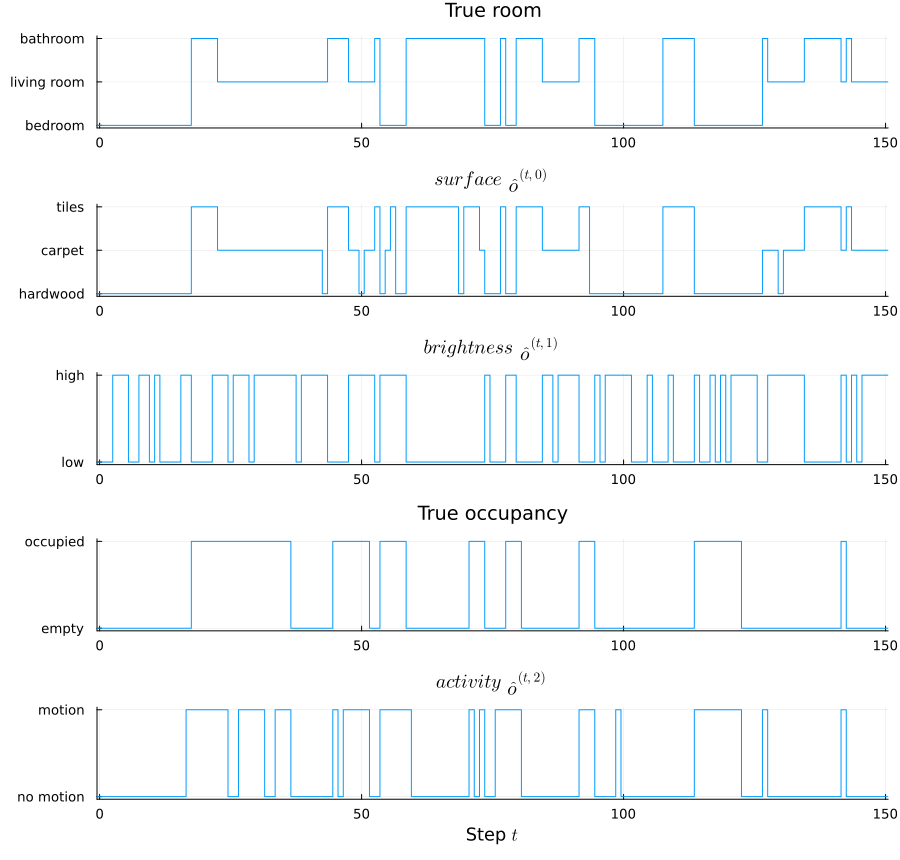

In [37]:
true_states = [argmax(Lŝˣ[station_n]) for Lŝˣ in parent(Lŝˣː)] ## station index 1..6
rooms       = (true_states .+ 1) .÷ 2               ## 1 bedroom, 2 living room, 3 bathroom
occupancies = iseven.(true_states) .+ 1             ## 1 empty, 2 occupied
surfaces    = [argmax(Lô[surface_m]) for Lô in parent(Lôː)]
brightnesses = [argmax(Lô[brightness_m]) for Lô in parent(Lôː)]
activities  = [argmax(Lô[activity_m]) for Lô in parent(Lôː)]

window = (-0.5, 150.5) ## zoom, so single ticks stay visible; (-0.5, T + 0.5) is the full run
## Tiles run from t - 0.5 to t + 0.5, so the step line and a later heatmap share tick t.
## xlabel is a single string on the bottom panel. A vector of strings is printed
## as one label, and the $ in "Step $t$" then makes GR report syntax errors.
panel(y, ticks, title; xlabel="") = plot(
    step_x(T+1), step_y(y), linetype=:steppost, label="",
    yticks=ticks, xlims=window, legend=:false, title=title, xlabel=xlabel)

plot(
    panel(rooms, (1:3, ["bedroom", "living room", "bathroom"]), "True room"),
    panel(surfaces, (1:3, surface_labels), raw"$\mathit{surface}$ $\hat{o}^{(t,0)}$"),
    panel(brightnesses, (1:2, brightness_labels), raw"$\mathit{brightness}$ $\hat{o}^{(t,1)}$"),
    panel(occupancies, (1:2, ["empty", "occupied"]), "True occupancy"),
    panel(activities, (1:2, activity_labels), raw"$\mathit{activity}$ $\hat{o}^{(t,2)}$"; xlabel=raw"Step $t$"),
    layout=(5, 1), size=(900, 860), link=:x,
)

In [38]:
## High-brightness fractions should come out near 0.50, 0.85 and 0.10.
## Misses near 0.20 of occupied ticks, false alarms near 0.05 of empty ticks.
## They are a sample, so they will not match the matrix exactly.
## A^{*(1)} stores one column per station; room r is column 2r-1 (empty) and 2r (occupied).
camera_mistakes = count(rooms .!= surfaces)
println("camera mistakes: $camera_mistakes of $(T+1) ticks ($(round(100*camera_mistakes/(T+1), digits=1))%)")

occupied     = occupancies .== 2
misses       = count(occupied .& (activities .== 1))    ## person present, "no motion"
false_alarms = count(.!occupied .& (activities .== 2))  ## empty, "motion"
println("motion sensor misses:       $misses of $(count(occupied)) occupied ticks ($(round(100*misses/count(occupied), digits=1))%)")
println("motion sensor false alarms: $false_alarms of $(count(.!occupied)) empty ticks ($(round(100*false_alarms/count(.!occupied), digits=1))%)")

for (r, room) in enumerate(["bedroom", "living room", "bathroom"])
    in_room   = rooms .== r
    frac_high = mean(brightnesses[in_room] .== 2)
    println("$room: high $(round(frac_high, digits=2)) of $(count(in_room)) ticks (A^{*(1)}: $(_Aˣı1ı[2, 2r-1]))")
end

camera mistakes: 53 of 600 ticks (8.8%)
motion sensor misses:       33 of 182 occupied ticks (18.1%)
motion sensor false alarms: 20 of 418 empty ticks (4.8%)
bedroom: high 0.48 of 235 ticks (A^{*(1)}: 0.5)
living room: high 0.87 of 166 ticks (A^{*(1)}: 0.85)
bathroom: high 0.07 of 199 ticks (A^{*(1)}: 0.1)


### 4.4 Uncertainty Model

The randomness in the environment is drawn in `create_envir`, from one `MersenneTwister`. `execute` samples the next *station* from $\boldsymbol{B}^{\ast(0)}$, and samples *surface*, *brightness* and *activity* from $\boldsymbol{A}^{\ast(0)}$, $\boldsymbol{A}^{\ast(1)}$ and $\boldsymbol{A}^{\ast(2)}$. The initial *station* is fixed, so `create_envir` does not sample it.

The agent is not given the environment's likelihoods. It learns $\boldsymbol{A}^{(m)}$ under the priors of 4.5.4, which are deliberately not the normalized columns of $\boldsymbol{A}^{\ast(m)}$. It is given the transition exactly: $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$. Its uncertainty about the matrices is the Dirichlet priors, not a feature of the environment. Its uncertainty about the *station* is the belief $\boldsymbol{s}^{(t,0)}$.

### 4.5 Agent / Generative Model
#### 4.5.1 State and Observation variables

The agent does not know the *station* at time $t$. It carries a belief, one probability vector for the single factor:

$$
\boldsymbol{s}^{(t,0)} \in [0,1]^{6}.
$$

Inside $P$ and $Q$ the state is the plain random variable $s^{(t,0)}$, and the tuple of random variables is $\mathbf{s}^{(t)} = \big(s^{(t,0)}\big)$. Outside them, the belief is the bold vector above. The belief is a structured mean-field approximation, not the exact posterior: the *station* trajectory keeps its dependence across time, and it is decoupled from the three likelihood matrices, which is what makes the inference tractable. Section 4.5.4 writes the factorization.

The room belief is the sum of the empty and occupied entries of each room. The belief that a person is present is the sum of the three occupied entries.

The initial prior is

$$
P_D\big(s^{(0,0)}\big) = \mathcal{Cat}\big(s^{(0,0)};\, \boldsymbol{D}^{(0)}\big),
$$

with $\boldsymbol{D}^{(0)} = [\tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}]^{\top}$. The agent does not know that the Roomba starts at "bedroom empty".

The observation tuple is the one the environment generates, $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big)$, with the same values as in 4.3.1.

**A worked belief.** Suppose $\boldsymbol{s}^{(t,0)} = [0.5, 0.2, 0.15, 0.05, 0.05, 0.05]^{\top}$, so the bedroom has probability 0.7, the living room 0.2, the bathroom 0.1, and a person is present with probability 0.3. Suppose $\boldsymbol{A}^{(0)}$ equals $\boldsymbol{A}^{\ast(0)}$. The expected *surface* is the matrix–vector product

$$
\boldsymbol{A}^{(0)}\,\boldsymbol{s}^{(t,0)} =
\begin{bmatrix}
0.9 & 0.9 & 0.05 & 0.05 & 0.05 & 0.05 \\
0.05 & 0.05 & 0.9 & 0.9 & 0.05 & 0.05 \\
0.05 & 0.05 & 0.05 & 0.05 & 0.9 & 0.9
\end{bmatrix}
\begin{bmatrix} 0.5 \\ 0.2 \\ 0.15 \\ 0.05 \\ 0.05 \\ 0.05 \end{bmatrix}
=
\begin{bmatrix} 0.645 \\ 0.22 \\ 0.135 \end{bmatrix}.
$$

That is "hardwood" with probability 0.645, "carpet" with 0.22, and "tiles" with 0.135. If the camera then reads "carpet", the received one-hot is $\hat{\boldsymbol{o}}^{(t,0)} = [0,1,0]^{\top}$, and the category is $\hat{o}^{(t,0)} = \text{carpet}$, linked by $\hat{o}^{[i]} = \delta_{i\hat{o}}$. The expected *activity* depends only on occupancy: with a person present at probability 0.3, "motion" has probability $0.05 \cdot 0.7 + 0.8 \cdot 0.3 = 0.275$.

The agent has both the expected reading and the received reading. It never has a hatted *station*. Only the environment has $\hat{\boldsymbol{s}}^{\ast(t,0)}$.

#### 4.5.2 Decision variables

There are no decision variables. There is no control factor, no horizon $H$, and no policy matrix $\boldsymbol{V}$.

#### 4.5.3 Preference variables / Setpoints

There are no preferences. $\log\boldsymbol{C}$ and the habit vector $\boldsymbol{E}$ are not in this part. Nothing is chosen, so a preference could not change a decision.

#### 4.5.4 State Transition and Observation Generation functions

The state transition is

$$
P_{B}\big(s^{(t,0)} \mid s^{(t-1,0)}\big) = \mathcal{Cat}\big(s^{(t,0)};\, \boldsymbol{B}^{(0)}[\bullet, s^{(t-1,0)}]\big).
$$

The column $\boldsymbol{B}^{(0)}[\bullet, s^{(t-1,0)}]$ is a bold vector: one index is free. In this part the agent is given $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$, so $\boldsymbol{B}^{(0)}$ is a known parameter, written as the subscript $B$, not a random variable.

The observation model, one sensor at a time, is

$$
P\big(o^{(t,m)} \mid s^{(t,0)}, \boldsymbol{A}^{(m)}\big) = \mathcal{Cat}\big(o^{(t,m)};\, \boldsymbol{A}^{(m)}[\bullet, s^{(t,0)}]\big), \qquad m = 0, 1, 2.
$$

An entry of $\boldsymbol{A}^{(m)}$ is the probability of one reading given one *station* value, and each column is a categorical distribution. The same holds for $\boldsymbol{B}^{(0)}$, with the next *station* in place of the reading. The agent does not know the *station*. It has the belief $\boldsymbol{s}^{(t,0)}$, and the matrix–vector product $\boldsymbol{A}^{(m)}\,\boldsymbol{s}^{(t,0)}$ is the expected reading: a weighted average of the columns. $\boldsymbol{B}^{(0)}\,\boldsymbol{s}^{(t-1,0)}$ is the predicted next belief.

Given the *station*, the three sensors are independent. The agent multiplies their likelihoods,

$$
P\big(o^{(t,0)}, o^{(t,1)}, o^{(t,2)} \mid s^{(t,0)}\big) = \prod_{m=0}^{2} P\big(o^{(t,m)} \mid s^{(t,0)}, \boldsymbol{A}^{(m)}\big).
$$

A value of the *station* that explains all three readings gains belief. *Surface* and *brightness* separate the rooms. *Activity* separates empty from occupied.

The likelihoods are learned. The priors are Dirichlet distributions over the columns, which RxInfer calls `DirichletCollection`:

$$
P_{\check{a}}\big(\boldsymbol{A}^{(m)}\big) = \mathcal{Dir}\big(\boldsymbol{A}^{(m)};\, \check{\boldsymbol{a}}^{(m)}\big), \qquad m = 0, 1, 2.
$$

$\log\boldsymbol{C}$ is not involved. Normalizing a preference would add the same constant to every policy, and there are no policies here. The concentration parameters are pseudo-counts.

**With the *surface* prior.** Large counts where the floor type matches the room, in both the empty and the occupied column, and a small count on the mistakes. The $3 \times 3$ pattern below is repeated once per occupancy, giving $3 \times 6$.

| *surface* \ room | bedroom | living room | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 10 | 1 | 1 |
| **carpet** | 1 | 10 | 1 |
| **tiles** | 1 | 1 | 10 |

**With the *brightness* prior.** Every entry is 1, a $2 \times 6$ matrix of ones. The agent does not know which rooms are bright. It learns $\boldsymbol{A}^{(1)}$ from the data, anchored by the camera.

**With the *activity* prior.** The $2 \times 2$ pattern below is repeated for each room, giving $2 \times 6$. "motion" is paired with the occupied columns, and "no motion" with the empty columns.

| *activity* \ occupancy | empty | occupied |
| --- | --- | --- | --- |
| **no motion** | 9 | 1 |
| **motion** | 1 | 9 |

Without that pairing, a flat prior would leave "empty" and "occupied" interchangeable. The prior fixes the meaning. The agent still learns the reliability from the data.

The transition is not learned. If inference goes poorly, it is not because the agent is still learning how the Roomba moves.

**Inference.** Variational inference uses a structured approximation. The *station* trajectory stays coupled across time, and it is decoupled from the three matrices:

$$
Q\big(s^{(0:T,0)}, \boldsymbol{A}^{(0)}, \boldsymbol{A}^{(1)}, \boldsymbol{A}^{(2)}\big) = Q\big(s^{(0:T,0)}\big)\, Q\big(\boldsymbol{A}^{(0)}\big)\, Q\big(\boldsymbol{A}^{(1)}\big)\, Q\big(\boldsymbol{A}^{(2)}\big).
$$

`compute` runs 20 iterations and keeps the last one. The Bethe free energy is recorded and should fall, then level off.

**Planning.** There is no planning. No policy is scored, and $\boldsymbol{G}$ is not formed.

#### 4.5.5 Implementation of the Agent / Generative Model / Internal Model

The generative model of one run is

$$
\begin{aligned}
&P\big(o^{(0:T,0)}, o^{(0:T,1)}, o^{(0:T,2)}, s^{(0:T,0)}, \boldsymbol{A}^{(0)}, \boldsymbol{A}^{(1)}, \boldsymbol{A}^{(2)}\big) \\[4pt]
&\quad= \underbrace{P_{\check{a}}\big(\boldsymbol{A}^{(0)}\big)\, P_{\check{a}}\big(\boldsymbol{A}^{(1)}\big)\, P_{\check{a}}\big(\boldsymbol{A}^{(2)}\big)}_{\text{parameter prior}}
   \,\underbrace{P_D\big(s^{(0,0)}\big)}_{\substack{\text{state}\\ \text{prior}}}
   \prod_{t=0}^{T} \prod_{m=0}^{2} \underbrace{P\big(o^{(t,m)} \mid s^{(t,0)}, \boldsymbol{A}^{(m)}\big)}_{\substack{\text{observation}\\ \text{model}}}
   \prod_{t=1}^{T} \underbrace{P_{B}\big(s^{(t,0)} \mid s^{(t-1,0)}\big)}_{\substack{\text{state}\\ \text{transition}}}.
\end{aligned}
$$

$\boldsymbol{D}^{(0)}$ and $\boldsymbol{B}^{(0)}$ are fixed, so they stay in the subscripts $D$ and $B$. The three likelihoods are random variables, so they appear as arguments. The product over $m$ is where the sensors combine: at each tick all three readings depend on the same *station*, and given that *station* they are independent.

The model does three steps, of which only the first runs in this part.

1. **Perception.** `compute` infers $Q\big(s^{(0:T,0)}\big)$ and the three matrix posteriors from the whole trajectory.
2. **Planning.** Not in this part.
3. **Decision.** Not in this part. `act` is unused.

States and readings are categorical. The priors on the likelihoods are the `DirichletCollection` values from 4.5.4.

In [39]:
@model function hidden_markov_model(oı0ıː, oı1ıː, oı2ıː, _Bı0ı, T)
    _Aı0ı ~ DirichletCollection(repeat([10.0  1.0  1.0;
                                        1.0 10.0  1.0;
                                        1.0  1.0 10.0], inner=(1, 2))) ## P_{ǎ}(A^{(0)}): surface, trusted camera (3×6)
    _Aı1ı ~ DirichletCollection(ones(2, 6))                             ## P_{ǎ}(A^{(1)}): brightness, flat (2×6)
    _Aı2ı ~ DirichletCollection(repeat([9.0 1.0;
                                        1.0 9.0], outer=(1, 3)))        ## P_{ǎ}(A^{(2)}): activity, motion suggests occupied (2×6)

    sı0ıː[1]  ~ Categorical(fill(1.0/6.0, 6))   ## t = 0: P_D(s^{(0,0)}), uniform
    oı0ıː[1] ~ DiscreteTransition(sı0ıː[1], _Aı0ı) ## t = 0: P(o^{(0,0)} | s^{(0,0)}, A^{(0)})
    oı1ıː[1] ~ DiscreteTransition(sı0ıː[1], _Aı1ı) ## t = 0: P(o^{(0,1)} | s^{(0,0)}, A^{(1)})
    oı2ıː[1] ~ DiscreteTransition(sı0ıː[1], _Aı2ı) ## t = 0: P(o^{(0,2)} | s^{(0,0)}, A^{(2)})
    for t in 1:T
        sı0ıː[t+1]  ~ DiscreteTransition(sı0ıː[t], _Bı0ı)  ## P_B(s^{(t,0)} | s^{(t-1,0)}), B given
        oı0ıː[t+1] ~ DiscreteTransition(sı0ıː[t+1], _Aı0ı) ## P(o^{(t,0)} | s^{(t,0)}, A^{(0)})
        oı1ıː[t+1] ~ DiscreteTransition(sı0ıː[t+1], _Aı1ı) ## P(o^{(t,1)} | s^{(t,0)}, A^{(1)})
        oı2ıː[t+1] ~ DiscreteTransition(sı0ıː[t+1], _Aı2ı) ## P(o^{(t,2)} | s^{(t,0)}, A^{(2)})
    end
end

@constraints function hidden_markov_model_constraints()
    q(sı0ıː, _Aı0ı, _Aı1ı, _Aı2ı) = q(sı0ıː)q(_Aı0ı)q(_Aı1ı)q(_Aı2ı)
end

hidden_markov_model_constraints (generic function with 1 method)

**Notes on the agent code.**

**Names.** The model mirrors the agent's math, and a model has no tuple to index.

- `sı0ıː`, `oı0ıː`, `oı1ıː` and `oı2ıː` have no hats and no leading `_`. They are the random variables $s^{(0:T,0)}$, $o^{(0:T,0)}$, $o^{(0:T,1)}$ and $o^{(0:T,2)}$. The data fills in the readings. In the model the `oı…ıː` names are still the variables being observed.
- `_Aı0ı`, `_Aı1ı`, `_Aı2ı` and `_Bı0ı` are the bold matrices $\boldsymbol{A}^{(0)}$, $\boldsymbol{A}^{(1)}$, $\boldsymbol{A}^{(2)}$ and $\boldsymbol{B}^{(0)}$. The member index sits in the name as `ı…ı`.
- `_Bı0ı` is an argument, not a random variable. It does not appear in the constraints. The call passes `_Bˣı0ı`, because $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$.
- A comment that implements a line of the generative model names that line. It does not repeat the formula.

**Structure.** The uniform prior is on $s^{(0,0)}$ itself, the sensors are attached at $t = 0$, and there are $T + 1 = 600$ ticks.

- The prior is on `sı0ıː[1]`, which is $t = 0$, and the first reading of each sensor is attached to it.
- At every tick all three readings attach to the same state. That is the product over $m$.
- The loop variable `t` is the math's $t$. The storage index is `t+1` only because RxInfer vectors start at 1, so `sı0ıː[t+1]` holds $s^{(t,0)}$.
- The constraint `q(sı0ıː)q(_Aı0ı)q(_Aı1ı)q(_Aı2ı)` is the factorization in 4.5.4.

The data go in under the model's observation names, one 1-based vector per sensor. The known transition goes in as `_Bı0ı`.

`DiscreteTransition` is the node older RxInfer versions called `Transition`. `DirichletCollection` is the prior older versions called `MatrixDirichlet`.

In [40]:
function create_agent(; _ôı0ıː_data, _ôı1ıː_data, _ôı2ıː_data, _Bı0ı)
    @assert length(_ôı0ıː_data) == length(_ôı1ıː_data) == length(_ôı2ıː_data) "all sensors must cover the same time steps"
    T = length(_ôı0ıː_data) - 1    ## observations at t = 0, ..., T

    compute = () -> begin
        imarginals = @initialization begin
            q(_Aı0ı) = DirichletCollection(ones(3, 6)) ## surface:    3 values × 6 station values
            q(_Aı1ı) = DirichletCollection(ones(2, 6)) ## brightness: 2 values × 6 station values
            q(_Aı2ı) = DirichletCollection(ones(2, 6)) ## activity:    2 values × 6 station values
            q(sı0ıː) = vague(Categorical, 6)
        end
        infer(
            model          = hidden_markov_model(_Bı0ı=_Bı0ı, T=T),
            data           = (oı0ıː = _ôı0ıː_data, oı1ıː = _ôı1ıː_data, oı2ıː = _ôı2ıː_data),
            constraints    = hidden_markov_model_constraints(),
            initialization = imarginals,
            returnvars     = (_Aı0ı = KeepLast(), _Aı1ı = KeepLast(), _Aı2ı = KeepLast(), sı0ıː = KeepLast()),
            iterations     = 20,
            free_energy    = true,
        )
    end

    act    = () -> error("act: this part has no actions")
    future = p -> error("future: this part has no policies")
    slide  = () -> error("slide: compute runs over the whole trajectory")
    return (act, future, compute, slide)
end

create_agent (generic function with 1 method)

#### 4.5.6 Expected free energy and action selection

Expected free energy is not used. There is no policy posterior $Q(\pi) = \sigma(-\boldsymbol{G}_{\Sigma})$, no habit vector $\boldsymbol{E}$, and no action posterior

$$
Q(u^{(t)}) = \sum_{p} \delta_{u = V^{[p,0]}}\, Q(\pi^{(t)} = p).
$$

Those formulas are what the next part will add, once the Roomba chooses a move and the preference for the *activity* value "no motion" is a vector $\log\boldsymbol{C}$. Giving $\log\boldsymbol{C}$ directly, rather than as the logarithm of a normalized distribution, will not matter: normalizing would add the same constant to every $G_{\Sigma}^{[p]}$ and would change no decision. Modalities that are only used for perception will keep $\log\boldsymbol{C} = \boldsymbol{0}$.

### 4.6 Agent Evaluation

The run below generates the environment at seed 42, the same seed as the test drive in 4.3.6, and then calls `compute` once on all 600 ticks. Variational inference starts from flat Dirichlet marginals on the three likelihoods and from `vague` on the *station*. It runs 20 iterations. `KeepLast` stores the final posterior at every tick, and the Bethe free energy is kept so we can see whether the iterations settled.

The detail run is one seed, so that the beliefs can be read tick by tick. A single run can be misleading. Averages over 30 seeds are not in this part. Appendix B records that as a caveat, not as a result.

In [41]:
## ---------- simulation parameters ----------
## T and Lŝˣ₀ are the run from 4.3.6: 600 ticks, start at "bedroom empty", seed 42.
T
Lŝˣ₀

1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [ ]:
## ---------- overrides ----------

In [42]:
## Environment: t = 0, ..., T, seed 42 (the default inside create_envir).
(execute_ai, observe_ai, state_ai) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)
Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}
for t = 0:T
    t > 0 && execute_ai()
    Lŝˣː[t] = state_ai()
    Lôː[t]  = observe_ai()
end

## Agent: one batch inference. B^{(0)} is given as _Bˣı0ı.
_ôı0ıː_data = [Lô[surface_m] for Lô in parent(Lôː)]
_ôı1ıː_data = [Lô[brightness_m] for Lô in parent(Lôː)]
_ôı2ıː_data = [Lô[activity_m] for Lô in parent(Lôː)]
(act_ai, future_ai, compute_ai, slide_ai) = create_agent(;
    _ôı0ıː_data=_ôı0ıː_data, _ôı1ıː_data=_ôı1ıː_data, _ôı2ıː_data=_ôı2ıː_data, _Bı0ı=_Bˣı0ı)
result = compute_ai()

Inference results:
  Posteriors       | available for (_Aı0ı, sı0ıː, _Aı1ı, _Aı2ı)
  Free Energy:     | [1519.49, 1395.52, 1172.21, 1064.99, 1029.77, 1023.61, 1022.76, 1022.59, 1022.53, 1022.5, 1022.49, 1022.48, 1022.48, 1022.47, 1022.47, 1022.47, 1022.47, 1022.47, 1022.47, 1022.47]


In [43]:
[station_labels[argmax(Lŝˣ[station_n])] for Lŝˣ in Lŝˣː] ## true station, t = 0, ..., T

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 "bedroom empty"
 ⋮
 "living room empty"
 "living room empty"
 "living room empty"
 "living room empty"
 "living room empty"
 "bathroom empty"
 "bathroom empty"
 "bathroom empty"
 "bathroom empty"

In [44]:
_Bı0ı = _Bˣı0ı    ## B^{(0)} = B^{*(0)}, given, not learned
_Bı0ı

6×6 Matrix{Float64}:
 0.855  0.09  0.0    0.0   0.07  0.07
 0.045  0.81  0.0    0.0   0.03  0.03
 0.0    0.0   0.855  0.09  0.05  0.05
 0.0    0.0   0.045  0.81  0.05  0.05
 0.09   0.09  0.09   0.09  0.76  0.08
 0.01   0.01  0.01   0.01  0.04  0.72

The matrix just printed is the *station* transition the agent was given. It is the $6 \times 6$ matrix of 4.3.4, not the $3 \times 3$ room block. An earlier draft compared it with that $3 \times 3$ block, which was left over from Part 2.

In [45]:
println("Posterior mean of A^{(0)} (surface):")
_Āı0ı = mean(result.posteriors[:_Aı0ı]) ## Ā^{(0)} = E_Q[A^{(0)}]

Posterior mean of A^{(0)} (surface):


3×6 Matrix{Float64}:
 0.91163    0.913019   0.0594208  0.0729868  0.0481594  0.0519372
 0.0249474  0.0332082  0.915264   0.866835   0.0641686  0.164049
 0.0634231  0.0537732  0.0253154  0.0601777  0.887672   0.784014

This compares well with `_Aˣı0ı`, the *surface* likelihood of 4.3.4:

```
0.90  0.90  0.05  0.05  0.05  0.05
0.05  0.05  0.90  0.90  0.05  0.05
0.05  0.05  0.05  0.05  0.90  0.90
```

In [46]:
println("Posterior mean of A^{(1)} (brightness):")
_Āı1ı = mean(result.posteriors[:_Aı1ı]) ## Ā^{(1)} = E_Q[A^{(1)}]

Posterior mean of A^{(1)} (brightness):


2×6 Matrix{Float64}:
 0.526824  0.518316  0.150915  0.105986  0.946619   0.857295
 0.473176  0.481684  0.849085  0.894014  0.0533808  0.142705

This compares well with `_Aˣı1ı`. The *brightness* prior was flat, so this matrix is learned from the data, anchored by the camera:

```
0.50  0.50  0.15  0.15  0.90  0.90
0.50  0.50  0.85  0.85  0.10  0.10
```

In [47]:
println("Posterior mean of A^{(2)} (activity):")
_Āı2ı = mean(result.posteriors[:_Aı2ı]) ## Ā^{(2)} = E_Q[A^{(2)}]

Posterior mean of A^{(2)} (activity):


2×6 Matrix{Float64}:
 0.947308  0.167289  0.971757   0.157233  0.920476   0.0635338
 0.052692  0.832711  0.0282432  0.842767  0.0795237  0.936466

This compares well with `_Aˣı2ı`. The prior only paired "motion" with the occupied columns. The hit rate and the false-alarm rate are what the data have to teach:

```
0.95  0.20  0.95  0.20  0.95  0.20
0.05  0.80  0.05  0.80  0.05  0.80
```

The figures that follow use the posterior $Q\big(s^{(t,0)}\big)$. The room marginal adds the empty and occupied entries of each room. The occupancy marginal adds the three occupied entries. The most probable room is the tracking rule for $J_{\text{room}}$. Occupancy uses the one-half rule: occupied when that sum exceeds 0.5.

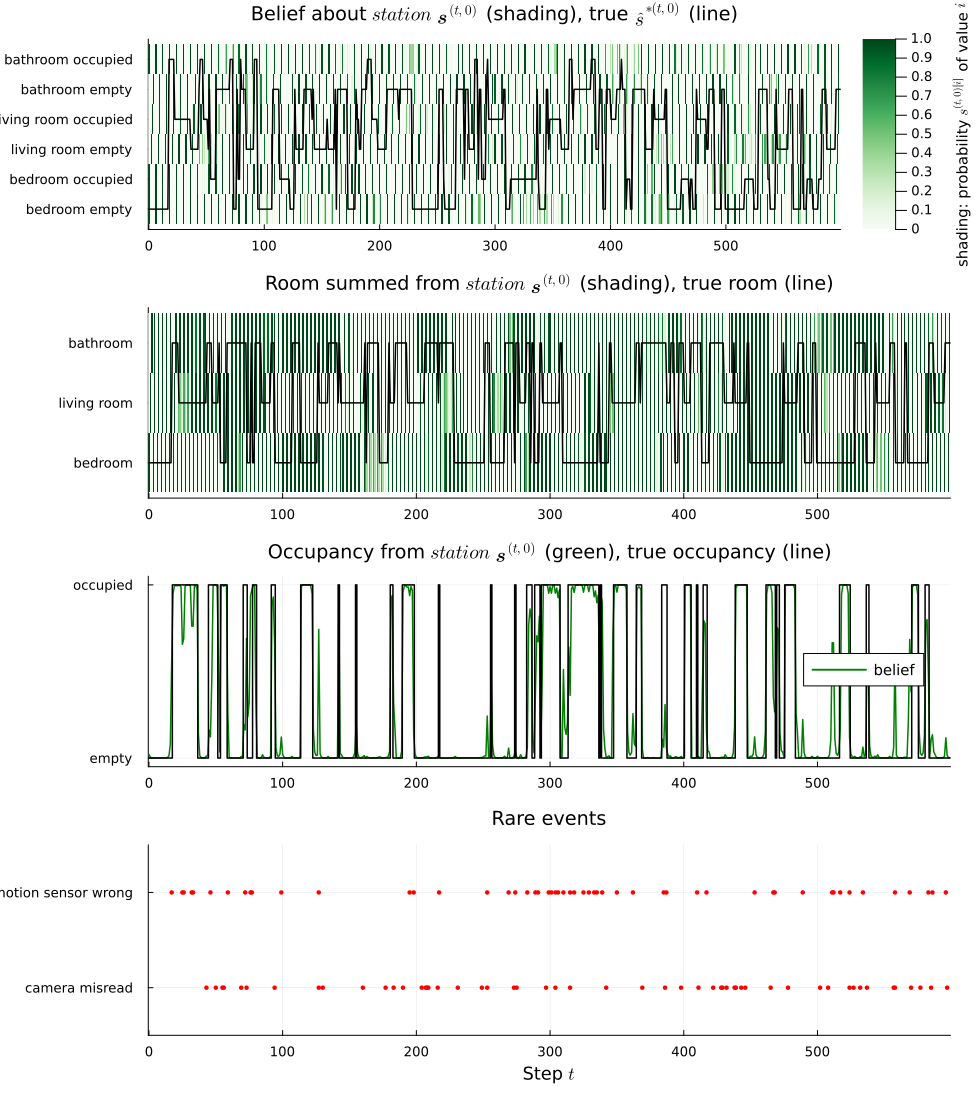

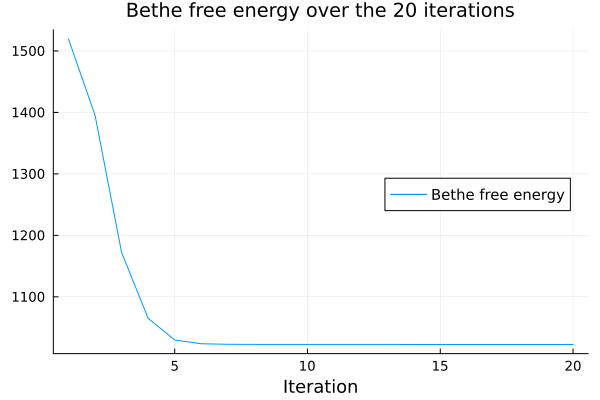

In [48]:
Lsː = offset0(result.posteriors[:sı0ıː])    ## Q(s^{(t,0)}), t = 0, ..., T

## Room marginal and occupancy marginal of one belief vector.
room_of(p) = [p[1] + p[2], p[3] + p[4], p[5] + p[6]]
occ_of(p)  = p[2] + p[4] + p[6]

true_states   = [argmax(Lŝˣ[station_n]) for Lŝˣ in parent(Lŝˣː)]
rooms         = (true_states .+ 1) .÷ 2
true_occupied = iseven.(true_states)

q_states       = [ReactiveMP.probvec(q) for q in parent(Lsː)]
inferred_rooms = [argmax(room_of(p)) for p in q_states]
p_occupied     = [occ_of(p) for p in q_states]
inferred_occ   = p_occupied .> 0.5          ## one-half rule; a tie at 0.5 counts as empty

J_room = mean(inferred_rooms .== rooms)     ## J_room
J_occ  = mean(inferred_occ .== true_occupied) ## J_occ

surfaces   = [argmax(Lô[surface_m]) for Lô in parent(Lôː)]
activities = [argmax(Lô[activity_m]) for Lô in parent(Lôː)]
## Camera baseline: hardwood → bedroom, carpet → living room, tiles → bathroom.
J_room_camera = mean(surfaces .== rooms)
## Motion-sensor baseline: "motion" means occupied.
J_occ_motion  = mean((activities .== 2) .== true_occupied)
camera_wrong  = surfaces .!= rooms
motion_wrong  = (activities .== 2) .!= true_occupied

_S = reduce(hcat, q_states)    ## 6 × (T+1). Plots wants (length(x), length(y)).
p_station = heatmap(0:T, 1:6, permutedims(_S), c=:Greens, clims=(0, 1),
    colorbar=:bottom,
    colorbar_title="shading: probability \$s^{(t,0)[i]}\$ of value \$i\$",
    yticks=(1:6, station_labels),
    xlims=(-0.5, T + 0.5), xticks=0:100:T, legend=:false,
    title="Belief about \$\\mathit{station}\$ \$\\mathbf{\\mathit{s}}^{(t,0)}\$ (shading), true \$\\hat{s}^{\\ast(t,0)}\$ (line)")
## The black line is the true category. Heatmap columns are centered on integer t.
plot!(p_station, step_x(T+1), step_y(true_states), color=:black, linewidth=1.5, label="")

room_belief = reduce(hcat, room_of.(q_states))    ## 3 × (T+1)
p_room = heatmap(0:T, 1:3, permutedims(room_belief), c=:Greens, clims=(0, 1),
    colorbar=false,
    yticks=(1:3, ["bedroom", "living room", "bathroom"]),
    xlims=(-0.5, T + 0.5), legend=:false,
    title="Room summed from \$\\mathit{station}\$ \$\\mathbf{\\mathit{s}}^{(t,0)}\$ (shading), true room (line)")
plot!(p_room, step_x(T+1), step_y(rooms), color=:black, linewidth=1.5, label="")

## The green line is a probability and the black line is the category.
## They meet when the belief is near 0 or 1, so neither line is shifted.
p_occ = plot(0:T, p_occupied, color=:green, linewidth=1.5, label="belief",
    xlims=(-0.5, T + 0.5), ylims=(-0.05, 1.05),
    yticks=([0, 1], ["empty", "occupied"]), legend=:right,
    title="Occupancy from \$\\mathit{station}\$ \$\\mathbf{\\mathit{s}}^{(t,0)}\$ (green), true occupancy (line)")
plot!(p_occ, step_x(T+1), step_y(Float64.(true_occupied)), color=:black, linewidth=1.5,
    linetype=:steppost, label="")

p_ev = scatter(findall(camera_wrong) .- 1, fill(1, count(camera_wrong)),
    color=:red, markersize=2.5, markerstrokewidth=0, label="",
    xlims=(-0.5, T + 0.5), ylims=(0.5, 2.5),
    yticks=(1:2, ["camera misread", "motion sensor wrong"]),
    xlabel="Step \$t\$", title="Rare events", legend=:false)
scatter!(p_ev, findall(motion_wrong) .- 1, fill(2, count(motion_wrong)),
    color=:red, markersize=2.5, markerstrokewidth=0, label="")

display(plot(p_station, p_room, p_occ, p_ev, layout=(4, 1), size=(980, 1100), link=:x))
plot(result.free_energy, label="Bethe free energy", xlabel="Iteration",
    title="Bethe free energy over the 20 iterations", legend=:right)

In the plot above, look for three things.

- The black line of the true *station* should sit on the dark green band of the belief. Where the band is pale and spread out, the agent is unsure.
- Red dots on the upper rare-event row are ticks where the camera misread the floor. The room panel should often stay correct there anyway, because the *station* persists and the other ticks anchor it.
- The occupancy panel should be smoother than the lower row of red dots. A single wrong *activity* reading does not always flip the belief. On this seed it also does not always get overruled. The measures below say how often.

In [49]:
## Measures of the seed-42 run. Higher is better for both J's.
println("J_room = $(round(100*J_room, digits=1))% of $(T+1) ticks")
println("J_occ  = $(round(100*J_occ, digits=1))% of $(T+1) ticks")
println("camera baseline, room:            $(round(100*J_room_camera, digits=1))%")
println("motion-sensor baseline, occupancy: $(round(100*J_occ_motion, digits=1))%")

J_room_when_camera_wrong = mean(inferred_rooms[camera_wrong] .== rooms[camera_wrong])
J_occ_when_motion_wrong  = mean(inferred_occ[motion_wrong] .== true_occupied[motion_wrong])
println("camera misread the floor at $(count(camera_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right room at $(round(100*J_room_when_camera_wrong, digits=1))% of those")
println("motion sensor was wrong at $(count(motion_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right occupancy at $(round(100*J_occ_when_motion_wrong, digits=1))% of those")

J_room = 97.8% of 600 ticks
J_occ  = 93.5% of 600 ticks
camera baseline, room:            91.2%
motion-sensor baseline, occupancy: 91.2%
camera misread the floor at 53 of 600 ticks; agent still inferred the right room at 88.7% of those
motion sensor was wrong at 53 of 600 ticks; agent still inferred the right occupancy at 49.1% of those


### 4.7 Conclusion and outlook

The agent watched a Roomba for 600 ticks. It received the *surface*, the *brightness* and the *activity*, and it did not choose an action. It had to infer the *station*: which room the Roomba was in, and whether a person was in that room. The transition was given. The three likelihoods were learned.

Three ingredients made this possible:

- **One *station* factor.** Six joint values let the model say that a person stays or leaves while the Roomba stays, and that a newly entered room is occupied at random. The room belief and the occupancy belief are sums of that one vector.
- **Each sensor has its own likelihood.** *Surface* and *brightness* depend only on the room. *Activity* depends only on whether a person is present. The product of the three likelihoods is what updates the *station*.
- **The *activity* prior pins the occupied columns.** Without the pairing of "motion" with those columns, "empty" and "occupied" would be interchangeable. The hit rate is still learned from the data.

The question of this part: with the transition known, can the agent track both the room and whether a person is present, when the motion sensor is noisy?

The figures and the printed measures in 4.6 are one run, seed 42, the same generator as the test drive. On that run the previous draft of this notebook recorded the following, and the cells above recompute them.

**The agent tracks the room more accurately than the camera, and it repairs most camera mistakes.** Room accuracy is 97.8%, against a camera baseline of 91.2% (53 mistakes in 600 ticks, 8.8%). On those 53 ticks the agent is still right 88.7% of the time.

**Occupancy accuracy beats the motion sensor by a small margin, and a wrong reading is not reliably overruled.** Occupancy accuracy is 93.5%, against a motion-sensor baseline of 91.2% (also 53 mistakes: 33 misses in 182 occupied ticks, 18.1%, and 20 false alarms in 418 empty ticks, 4.8%). On the 53 ticks the sensor is wrong, the agent is right only 49.1% of the time. Persistence helps on some of those ticks and not on others. The *brightness* sample is close to the matrix: "high" on 0.48 of bedroom ticks, 0.87 of living-room ticks, and 0.07 of bathroom ticks, against 0.50, 0.85 and 0.10.

| strategy | room accuracy | occupancy accuracy |
| --- | --- | --- |
| camera baseline | 91.2% | – |
| motion-sensor baseline | – | 91.2% |
| agent, seed 42 | 97.8% | 93.5% |

**The Bethe free energy falls and then levels off inside the 20 iterations.** The second plot in 4.6 is that curve. The run has settled. It does not by itself say that the beliefs are right. The table above is what says that.

**Caveats.** This is one seed. A single run can be misleading, and the series standard is an average over 30 seeds. Those averages are not computed here. The probabilities in 4.3.4 are assumed. The occupancy result depends on the *activity* prior: a flat prior would swap the meaning of the empty and occupied columns, and the 93.5% would not be a result about people. The 49.1% is the computed reminder that a wrong motion reading is often not repaired.

**Possible next steps.**

- **Learn the transition.** Let the agent learn $\boldsymbol{B}^{(0)}$ as well, as Part 2 did for the room block, and see whether occupancy inference holds up.
- **Choose actions.** Give the Roomba a preference for the *activity* value "no motion", one transition per action, and turn on `act`, `future` and `slide`. The outside score becomes $J_{\text{disturb}}$.
- **Average 30 seeds.** Report $J_{\text{room}}$ and $J_{\text{occ}}$ with the seed count, once this single run is confirmed.

The Roomba will then no longer only be tracked: it will choose to avoid company.

## APPENDIX A: Text conventions and their motivation

Three styles, each with one job. Italic lower case is a model variable: *station*, *surface*, *brightness*, *activity*. Double quotes are a value, and they match the label strings, so a search for `"living room empty"` hits the text and `station_labels`. Bold is a low-level heading or a label. Backticks are code. Italics and bold are not emphasis, and this notebook does not use underlining.

A name is written in lower case even at the start of a sentence, so the sentence starts with a word: "The *station* has six values." The words of a name are separated by spaces. Only model variables are italic. $J_{\text{room}}$, $J_{\text{occ}}$, $p_{\text{stay}}$ and $p_{\text{occ}}$ are plain, because they are measures and parameters.

Names in this notebook, and the words they replace:

| previous draft | name now | why |
|---|---|---|
| RoomOccupancy | *station* | "room" and "occupancy" are ordinary words, and both are used in the names of the measures |
| Texture | *surface* | "texture" is the ordinary word for the floor type the camera can mistake |
| Light | *brightness* | "light" is the ordinary word for the sensor and for the skylights |
| Motion | *activity* | "motion" is the ordinary word for what the motion sensor detects, and one of its two values |

The values changed from hyphenated tokens to phrases with spaces: "bedroom-empty" became "bedroom empty", and "livingroom-empty" became "living room empty". The indices did not change. The previous draft of this part used the old names. Earlier parts of the series should take these names when they are next revised.

Julia specifics that the text conventions bump into:

- A single quote marks a character, not a string. Strings in the code use double quotes, as the values do.
- `ˣ` is typed `\^x` then Tab. It is the environment's asterisk, and it is not an `x`.
- `ı` is typed `\imath` then Tab. It brackets a member index, as in `_Aˣı0ı`. It is not the letter i.
- `ː` marks a trajectory, `ₜ` the current tick, `ₜ₋₁` the previous tick. Those subscripts are legal in Julia identifiers.
- A leading `_` means the math symbol is bold. These notebooks are not imported as modules, so that use does not clash with a private name.
- GR plot titles use one math chunk per word, and italic bold as `\mathbf{\mathit{s}}`. They do not use `\boldsymbol`.

The motivation for keeping each style to one job is the one in the series standards: a reader can see when a word is a variable, when it is a value, and when it is code, without a second meaning for the same marks.

## APPENDIX B: Modeling choices and assumptions, and their motivation

Each choice is recorded so that it is not undone by accident. The numbers were assumed. When a measured value arrives, this is the list to edit.

**One factor for the room and the person.** Two factors would look simpler, and a later part may split them. One factor is what lets the transition say that the person in the next room does not depend on the room the Roomba just left. A product of two independent transitions cannot say that the occupancy is redrawn exactly when the room changes, and copied, with persistence, when the room stays. The cost is six states instead of three plus two, and beliefs about the room and about occupancy are sums rather than factors of their own.

**The transition is given.** Part 2 learned the room block. This part gives $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$ so that a failure of occupancy inference is not confused with a transition that is still being learned. The alternative, learning both, is the first item in the next steps of 4.7.

**The three priors are not the same.** The camera prior is peaked, with pseudo-counts 10 and 1, because the floor types are known and the camera is mostly right. The *brightness* prior is all ones, because Part 2 showed that this sensor barely helps, and we want the data to produce $\boldsymbol{A}^{(1)}$ rather than a prior that already knows the skylights. The *activity* prior has pseudo-counts 9 and 1, only to pin "motion" to the occupied columns. A flat *activity* prior was rejected: the labels "empty" and "occupied" would trade places and $J_{\text{occ}}$ would become meaningless.

**The light sensor stays.** It adds little. Removing it would make this part harder to compare with Part 2, so it stays, with a flat prior.

**The numbers.** $\boldsymbol{B}_{\text{room}}$ is the matrix from the earlier parts, including the missing door. $p_{\text{stay}}(\text{empty}) = 0.95$ and $p_{\text{stay}}(\text{occupied}) = 0.90$ say that people stay for a while but not forever. $p_{\text{occ}}$ is 0.30, 0.50 and 0.10 so the living room is the busy room and the bathroom is the quiet one. The camera is correct with probability 0.90. "high" has probability 0.50, 0.85 and 0.10 in the three rooms. The motion sensor detects a person with probability 0.80 and false-alarms with probability 0.05. None of these were measured.

**The agent does not know the initial state.** The environment starts at "bedroom empty". The agent's $\boldsymbol{D}^{(0)}$ is uniform. Giving it the true initial state would inflate the early accuracy and hide how fast the sensors identify the *station*.

**Structured mean-field.** $Q$ factorizes the *station* trajectory from the three matrices, and it does not factorize the trajectory itself. A fully factorized $Q$ over time would throw away the persistence that occupancy inference depends on. The exact posterior is intractable once the matrices are unknown.

**One batch, not a per-tick slide.** RxInfer's `compute` runs one inference over $t = 0, \ldots, T$. `slide` is unused on purpose. A filtering agent that updates once per tick would be a different algorithm, and it is not claimed here.

**Seed 42, one run.** The detail plots need one trajectory. The printed percentages in 4.7 are that run, recomputed by 4.6. They are not an average over 30 seeds. The camera and the motion sensor are the baselines. There is no "always act" baseline, because the agent does not act.

**The $3 \times 3$ comparison under the transition was a leftover.** It showed $\boldsymbol{B}_{\text{room}}$ where the given matrix is $6 \times 6$. The comparison in 4.6 now points at the joint matrix. The numbers in the model were not changed.

**Hyphenated value tokens became phrases.** "bedroom-empty" is now "bedroom empty". This is a label change. The column order, the `idx` map, the priors and the sampling are the same, so a seed-42 run should reproduce the previous draft's trajectory and the previous draft's posteriors.